In [12]:
import pandas as pd
import torch
import numpy as np
import random

In [13]:
import pandas as pd
import torch
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler

In [14]:
train_df = pd.read_csv("../data/burgers_train.csv")
test_df = pd.read_csv("../data/burgers_test.csv")

In [15]:
import itertools
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from neuralop.models import FNO
from torch.utils.data import DataLoader, TensorDataset


def prepare_fno2d_loaders(train_df, test_df, Nx=32, Nt=500, batch_size=32):
    """Formats wide DataFrames into PyTorch DataLoaders for FNO2D (CPU Native)."""

    def process(df):
        num_samples = len(df)
        total_mesh = Nx * Nt
        vals = df.values

        # Unpack indices based on data generation structure
        x_flat = vals[:, 3 : 3 + total_mesh]
        t_flat = vals[:, 3 + total_mesh : 3 + 2 * total_mesh]
        u_flat = vals[:, 3 + 2 * total_mesh :]

        # Reshape to [Samples, Nt, Nx]
        x_mesh = torch.tensor(x_flat.reshape(num_samples, Nt, Nx), dtype=torch.float32)
        t_mesh = torch.tensor(t_flat.reshape(num_samples, Nt, Nx), dtype=torch.float32)
        u_mesh = torch.tensor(u_flat.reshape(num_samples, Nt, Nx), dtype=torch.float32)

        # Create initial condition channel repeated over time dimension
        u_init = u_mesh[:, 0, :].unsqueeze(1).repeat(1, Nt, 1)

        # Stack into [Samples, Nt, Nx, Channels] -> Channels: [u_init, x, t]
        X = torch.stack([u_init, x_mesh, t_mesh], dim=-1)
        Y = u_mesh.unsqueeze(-1)  # Target: [Samples, Nt, Nx, 1]

        # Permute to neuralop's standard layout: [Samples, Channels, Nt, Nx]
        X = X.permute(0, 3, 1, 2)
        Y = Y.permute(0, 3, 1, 2)

        return TensorDataset(X, Y)

    train_loader = DataLoader(
        process(train_df), batch_size=batch_size, shuffle=True
    )
    test_loader = DataLoader(process(test_df), batch_size=batch_size, shuffle=False)

    return train_loader, test_loader

In [16]:
import itertools
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from neuralop.models import FNO
from torch.utils.data import DataLoader, TensorDataset

In [17]:
PARAM_SPACE = {
    "n_modes": [
        (8, 8),
        (12, 12),
        (16, 16),
        (24, 16),
    ],  # (modes_t, modes_x) -> spatial modes_x must be <= Nx//2 (16)
    "hidden_channels": [16, 32, 64], 
    "n_layers": [2, 3, 4],
    "lr": [1e-3, 3e-3, 5e-3],
    "weight_decay": [1e-6, 1e-4, 0.0],
}


def sample_hyperparameters(space):
    """Randomly extracts a parameter configuration."""
    return {k: random.choice(v) for k, v in space.items()}

In [18]:
class RelativeL2Loss(object):
    """Calculates the relative L2 norm error over grid fields."""

    def __call__(self, y_pred, y_true):
        num_examples = y_pred.size(0)
        diff_norms = torch.norm(
            y_pred.reshape(num_examples, -1) - y_true.reshape(num_examples, -1), 2, 1
        )
        true_norms = torch.norm(y_true.reshape(num_examples, -1), 2, 1)
        return torch.mean(diff_norms / (true_norms + 1e-8))


def train_and_evaluate(config, train_loader, test_loader, epochs=10):
    """Trains an FNO instance natively on the CPU under a specific config."""

    # Initialize neuralop FNO model on CPU
    model = FNO(
        n_modes=config["n_modes"],
        hidden_channels=config["hidden_channels"],
        n_layers=config["n_layers"],
        in_channels=3,  # u_init, x, t
        out_channels=1,  # u(x,t)
    )

    optimizer = torch.optim.AdamW(
        model.parameters(), lr=config["lr"], weight_decay=config["weight_decay"]
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    criterion = RelativeL2Loss()

    best_val_loss = float("inf")

    for epoch in range(epochs):
        model.train()
        for X_batch, Y_batch in train_loader:
            optimizer.zero_grad()
            output = model(X_batch)
            loss = criterion(output, Y_batch)
            loss.backward()
            optimizer.step()

        scheduler.step()

        # Evaluation phase
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for X_batch, Y_batch in test_loader:
                output = model(X_batch)
                val_loss += criterion(output, Y_batch).item() * X_batch.size(0)

        val_loss /= len(test_loader.dataset)
        if val_loss < best_val_loss:
            best_val_loss = val_loss

    return best_val_loss

In [19]:
train_loader, test_loader = prepare_fno2d_loaders(
    train_df, test_df, Nx=32, Nt=500, batch_size=32
)

In [10]:
train_loader, test_loader = prepare_fno2d_loaders(
    train_df, test_df, Nx=32, Nt=500, batch_size=32
)

# Search control parameters (optimized for CPU time considerations)
NUM_SEARCH_ITERATIONS = 10
EPOCHS_PER_RUN = 10

best_overall_loss = float("inf")
best_overall_config = None
search_history = []

print("Starting Random Search on CPU...")

for trial in range(NUM_SEARCH_ITERATIONS):
    current_config = sample_hyperparameters(PARAM_SPACE)
    print(f"\n--- Trial {trial + 1}/{NUM_SEARCH_ITERATIONS} ---")
    print(f"Testing Config: {current_config}")

    score = train_and_evaluate(
        current_config, train_loader, test_loader, epochs=EPOCHS_PER_RUN
    )
    print(f"Trial Best Val Relative L2 Loss: {score:.5f}")

    search_history.append({"config": current_config, "loss": score})

    if score < best_overall_loss:
        best_overall_loss = score
        best_overall_config = current_config
        print(" New overall best parameter set discovered!")

print("\n SEARCH COMPLETE ")
print(f"Best Relative L2 Error Achieved: {best_overall_loss:.5f}")
print(f"Best Configuration Found: {best_overall_config}")

Starting Random Search on CPU...

--- Trial 1/10 ---
Testing Config: {'n_modes': (16, 16), 'hidden_channels': 64, 'n_layers': 3, 'lr': 0.005, 'weight_decay': 1e-06}
Trial Best Val Relative L2 Loss: 0.04323
 New overall best parameter set discovered!

--- Trial 2/10 ---
Testing Config: {'n_modes': (12, 12), 'hidden_channels': 16, 'n_layers': 4, 'lr': 0.003, 'weight_decay': 1e-06}
Trial Best Val Relative L2 Loss: 0.08236

--- Trial 3/10 ---
Testing Config: {'n_modes': (8, 8), 'hidden_channels': 64, 'n_layers': 3, 'lr': 0.003, 'weight_decay': 0.0001}
Trial Best Val Relative L2 Loss: 0.04773

--- Trial 4/10 ---
Testing Config: {'n_modes': (8, 8), 'hidden_channels': 32, 'n_layers': 2, 'lr': 0.003, 'weight_decay': 1e-06}
Trial Best Val Relative L2 Loss: 0.06884

--- Trial 5/10 ---
Testing Config: {'n_modes': (12, 12), 'hidden_channels': 16, 'n_layers': 2, 'lr': 0.001, 'weight_decay': 0.0001}
Trial Best Val Relative L2 Loss: 0.19055

--- Trial 6/10 ---
Testing Config: {'n_modes': (12, 12), 'h

In [11]:
# --- Retrain the Best Model ---
print("\n================ RETRAINING BEST MODEL ================")
print(f"Using Configuration: {best_overall_config}")

# 1. Initialize the final model with best hyperparameters
final_model = FNO(
    n_modes=best_overall_config["n_modes"],
    hidden_channels=best_overall_config["hidden_channels"],
    n_layers=best_overall_config["n_layers"],
    in_channels=3,  # u_init, x, t
    out_channels=1,  # u(x,t)
)

# 2. Setup optimization tools
optimizer = torch.optim.AdamW(
    final_model.parameters(),
    lr=best_overall_config["lr"],
    weight_decay=best_overall_config["weight_decay"],
)

# Scale up scheduler iterations to 100 epochs
FINAL_EPOCHS = 100
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=FINAL_EPOCHS
)
criterion = RelativeL2Loss()

# Trackers for plotting performance curves later
train_loss_history = []
val_loss_history = []

# 3. Training loop execution
for epoch in range(1, FINAL_EPOCHS + 1):
    final_model.train()
    running_train_loss = 0.0

    for X_batch, Y_batch in train_loader:
        optimizer.zero_grad()
        output = final_model(X_batch)
        loss = criterion(output, Y_batch)
        loss.backward()
        optimizer.step()

        running_train_loss += loss.item() * X_batch.size(0)

    scheduler.step()

    # Calculate average training loss for the epoch
    epoch_train_loss = running_train_loss / len(train_loader.dataset)
    train_loss_history.append(epoch_train_loss)

    # Validation Phase
    final_model.eval()
    running_val_loss = 0.0

    with torch.no_grad():
        for X_batch, Y_batch in test_loader:
            output = final_model(X_batch)
            val_loss = criterion(output, Y_batch)
            running_val_loss += val_loss.item() * X_batch.size(0)

    epoch_val_loss = running_val_loss / len(test_loader.dataset)
    val_loss_history.append(epoch_val_loss)

    # Print updates every 10 epochs to keep the console clean
    if epoch == 1 or epoch % 10 == 0:
        print(
            f"Epoch [{epoch:3d}/{FINAL_EPOCHS}] | Train Loss: {epoch_train_loss:.5f} | Val Loss: {epoch_val_loss:.5f}"
        )

print("\nRetraining complete!")
print(f"Final Validation Relative L2 Error: {val_loss_history[-1]:.5f}")

# 4. Save the model weights
model_save_path = "best_fno2d_burgers.pt"
torch.save(final_model.state_dict(), model_save_path)
print(f" Model weights successfully saved to '{model_save_path}'")


================ RETRAINING BEST MODEL ================
Using Configuration: {'n_modes': (16, 16), 'hidden_channels': 64, 'n_layers': 3, 'lr': 0.005, 'weight_decay': 1e-06}
Epoch [  1/100] | Train Loss: 0.53736 | Val Loss: 0.24940
Epoch [ 10/100] | Train Loss: 0.05118 | Val Loss: 0.04634
Epoch [ 20/100] | Train Loss: 0.05357 | Val Loss: 0.05076
Epoch [ 30/100] | Train Loss: 0.05001 | Val Loss: 0.04772
Epoch [ 40/100] | Train Loss: 0.04623 | Val Loss: 0.04671
Epoch [ 50/100] | Train Loss: 0.04538 | Val Loss: 0.04788
Epoch [ 60/100] | Train Loss: 0.04355 | Val Loss: 0.04278
Epoch [ 70/100] | Train Loss: 0.04188 | Val Loss: 0.04279
Epoch [ 80/100] | Train Loss: 0.04110 | Val Loss: 0.04257
Epoch [ 90/100] | Train Loss: 0.04073 | Val Loss: 0.04199
Epoch [100/100] | Train Loss: 0.04058 | Val Loss: 0.04197

Retraining complete!
Final Validation Relative L2 Error: 0.04197
 Model weights successfully saved to 'best_fno2d_burgers.pt'


In [10]:
import os
import matplotlib.pyplot as plt
import numpy as np
import torch

output_dir = "fno_burgers_plots"
os.makedirs(output_dir, exist_ok=True)


final_model.eval()
all_preds = []
all_targets = []

with torch.no_grad():
    for X_batch, Y_batch in test_loader:
        # X_batch shape: [Batch, 3, Nt, Nx]
        output = final_model(X_batch)  # Shape: [Batch, 1, Nt, Nx]

        all_preds.append(output.squeeze(1).numpy())  # Remove channel dimension
        all_targets.append(Y_batch.squeeze(1).numpy())

all_preds = np.concatenate(all_preds, axis=0)  # Shape: (N_test, Nt, Nx)
all_targets = np.concatenate(all_targets, axis=0)  # Shape: (N_test, Nt, Nx)

# Extract spatial (x) and temporal (t) axes for plotting scales
# Grabbing from the first test sample's input features
with torch.no_grad():
    sample_input, _ = test_loader.dataset[0]
    # Channels: 0=u_init, 1=x_mesh, 2=t_mesh
    x_axis = sample_input[1, 0, :].numpy()  # 1D line of spatial points (Nx)
    time_axis = sample_input[2, :, 0].numpy()  # 1D line of time points (Nt)

# Compute absolute error map across space-time sheets
abs_error_map = np.abs(all_targets - all_preds)


NameError: name 'final_model' is not defined

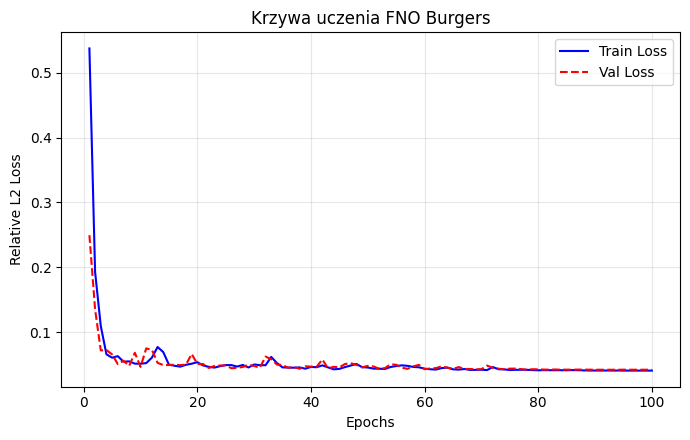

In [14]:
plt.figure(figsize=(7, 4.5))
plt.plot(
    range(1, FINAL_EPOCHS + 1),
    train_loss_history,
    label="Train Loss",
    color="blue",
    linewidth=1.5,
)
plt.plot(
    range(1, FINAL_EPOCHS + 1),
    val_loss_history,
    label="Val Loss",
    color="red",
    linestyle="--",
    linewidth=1.5,
)
plt.xlabel("Epochs")
plt.ylabel("Relative L2 Loss")
plt.title("Krzywa uczenia FNO Burgers")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Save Plot 1
plot1_path = os.path.join(output_dir, "loss_history_FNO_Burgers.png")
plt.savefig(plot1_path, dpi=300, bbox_inches="tight")
plt.show()

In [23]:
import torch
from neuralop.models import FNO

# 1. Recreate the exact same configuration dictionary
config = {
    'n_modes': (16, 16),
    'hidden_channels': 64,
    'n_layers': 3,
}

# 2. Re-instantiate the model architecture
# Note: based on your script, in_channels MUST be 3 (u_init, x, t)
model = FNO(
    n_modes=config['n_modes'],
    hidden_channels=config['hidden_channels'],
    n_layers=config['n_layers'],
    in_channels=3,  
    out_channels=1
)

# 3. Load the saved state dict, explicitly forcing it onto the CPU
weights_path = 'best_fno2d_burgers.pt'
state_dict = torch.load(weights_path, map_location='cpu')

# 4. Load the weights into your model
model.load_state_dict(state_dict)

# 5. Set the model to evaluation mode for inference
model.eval()
all_preds = []
all_targets = []

with torch.no_grad():
    for X_batch, Y_batch in test_loader:
        # X_batch shape: [Batch, 3, Nt, Nx]
        output = model(X_batch)  # Shape: [Batch, 1, Nt, Nx]

        all_preds.append(output.squeeze(1).numpy())  # Remove channel dimension
        all_targets.append(Y_batch.squeeze(1).numpy())

all_preds = np.concatenate(all_preds, axis=0)  # Shape: (N_test, Nt, Nx)
all_targets = np.concatenate(all_targets, axis=0)  # Shape: (N_test, Nt, Nx)

# Extract spatial (x) and temporal (t) axes for plotting scales
# Grabbing from the first test sample's input features
with torch.no_grad():
    sample_input, _ = test_loader.dataset[0]
    # Channels: 0=u_init, 1=x_mesh, 2=t_mesh
    x_axis = sample_input[1, 0, :].numpy()  # 1D line of spatial points (Nx)
    time_axis = sample_input[2, :, 0].numpy()  # 1D line of time points (Nt)

# Compute absolute error map across space-time sheets
abs_error_map = np.abs(all_targets - all_preds)



C:\Users\antek\AppData\Local\Temp\ipykernel_6564\2198657741.py:23: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state_dict = torch.load(weights_path, map_location='cpu')


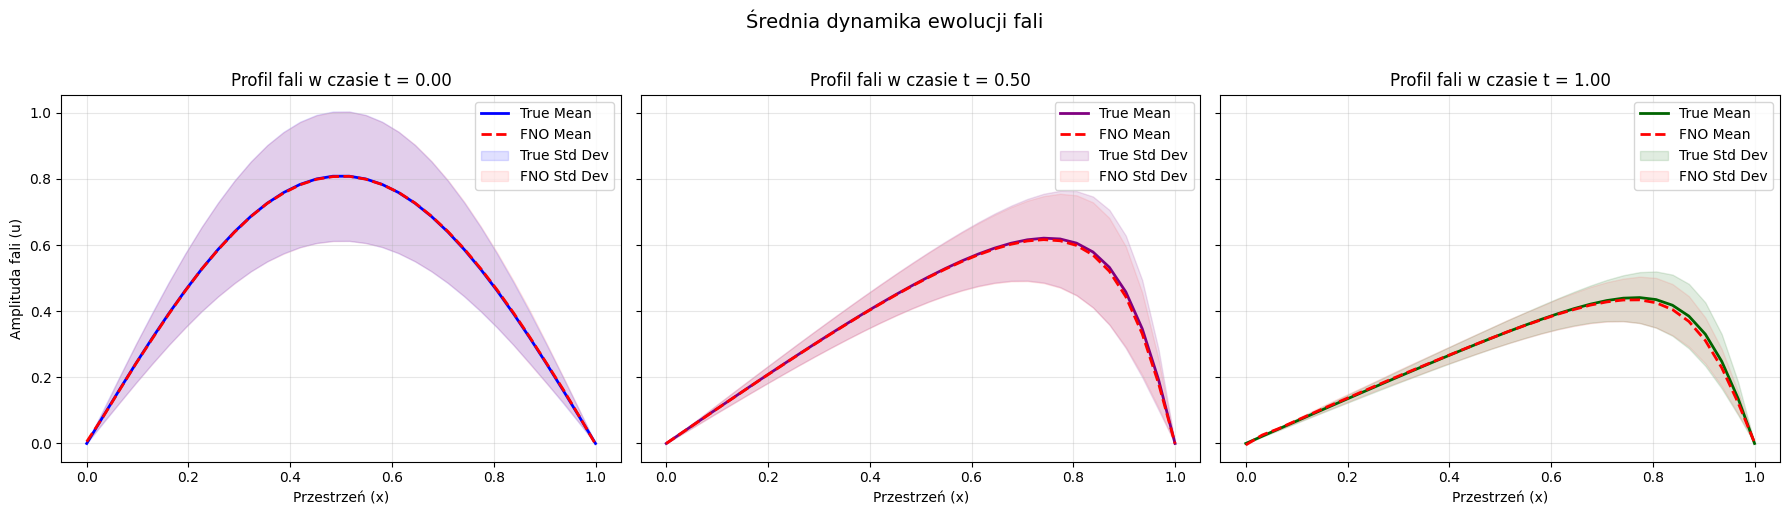

In [21]:
# Compute means and standard deviations across all validation profiles
# Shape of arrays: [Samples, Nt, Nx]
mean_target = all_targets_mesh.mean(axis=0)  # Shape: [Nt, Nx]
mean_pred = all_preds_mesh.mean(axis=0)  # Shape: [Nt, Nx]
std_target = all_targets_mesh.std(axis=0)  # Shape: [Nt, Nx]
std_pred = all_preds_mesh.std(axis=0)  # NOWY ELEMENT: Odchylenie standardowe dla predykcji

# Pick temporal indexes to review (Initial wave form, midpoint, final dissipation state)
time_slices = [0, len(time_axis) // 2, -1]
slice_colors = ["blue", "purple", "darkgreen"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

for idx, t_idx in enumerate(time_slices):
    actual_t = time_axis[t_idx]

    # Ground truth mean profile
    axes[idx].plot(
        x_axis,
        mean_target[t_idx],
        color=slice_colors[idx],
        linewidth=2,
        label="Prawdziwa Średnia",
    )

    # Conv-DeepONet mean profile prediction
    axes[idx].plot(
        x_axis,
        mean_pred[t_idx],
        color="red",
        linestyle="--",
        linewidth=2,
        label="Średnia DeepONet",
    )

    # Fill boundaries showing physical deviation distribution across the dataset
    axes[idx].fill_between(
        x_axis,
        mean_target[t_idx] - std_target[t_idx],
        mean_target[t_idx] + std_target[t_idx],
        color=slice_colors[idx],
        alpha=0.12,
        label="Prawdziwe Odchylenie",
    )

    axes[idx].fill_between(
        x_axis,
        mean_pred[t_idx] - std_pred[t_idx],
        mean_pred[t_idx] + std_pred[t_idx],
        color="red",
        alpha=0.08, 
        label="Odchylenie DeepONet",
    )

    axes[idx].set_title(f"Profil fali w czasie t = {actual_t:.2f}")
    axes[idx].set_xlabel("Przestrzeń (x)")

    if idx == 0:
        axes[idx].set_ylabel("Amplituda fali (u)")
    axes[idx].legend(loc="upper right")
    axes[idx].grid(True, alpha=0.3)

plt.suptitle(
    "Średnia dynamika ewolucji fali (Conv-DeepONet)", fontsize=14, y=1.02
)
plt.tight_layout()

# Save the statistics profile analysis sheet
plot3_path = os.path.join(output_dir, "Burgers_DeepONet_averages.png")
plt.savefig(plot3_path, dpi=300, bbox_inches="tight")
plt.show()

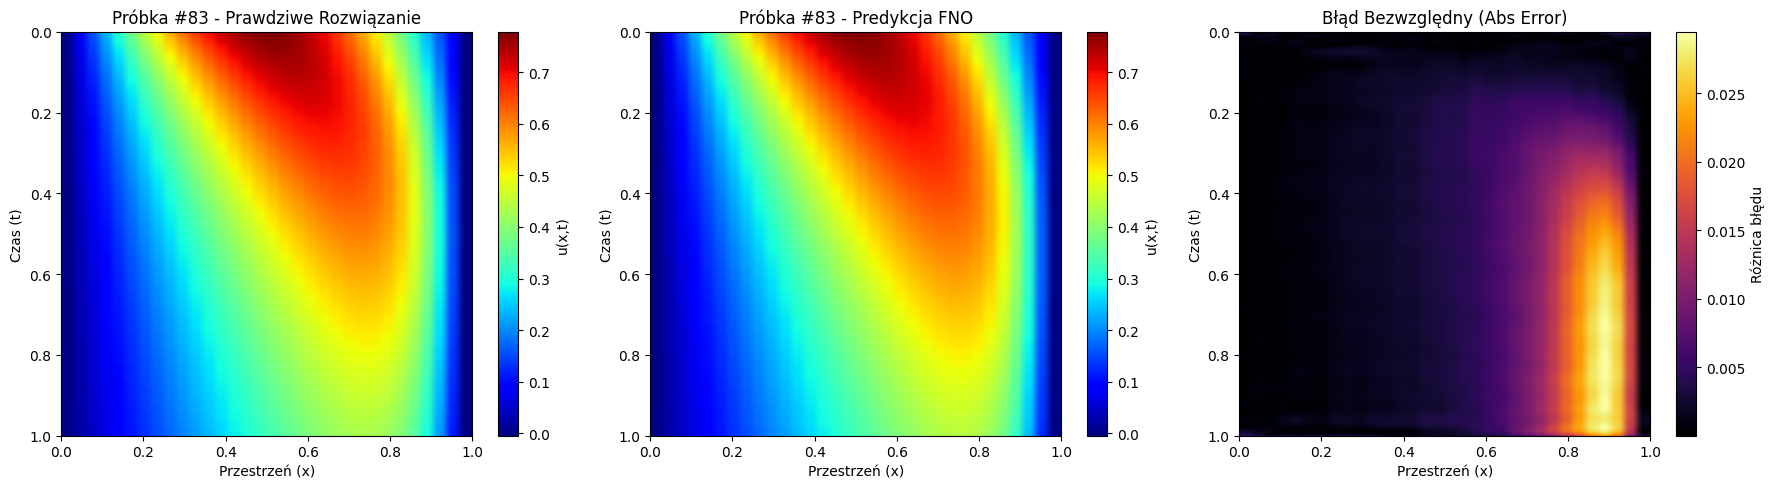

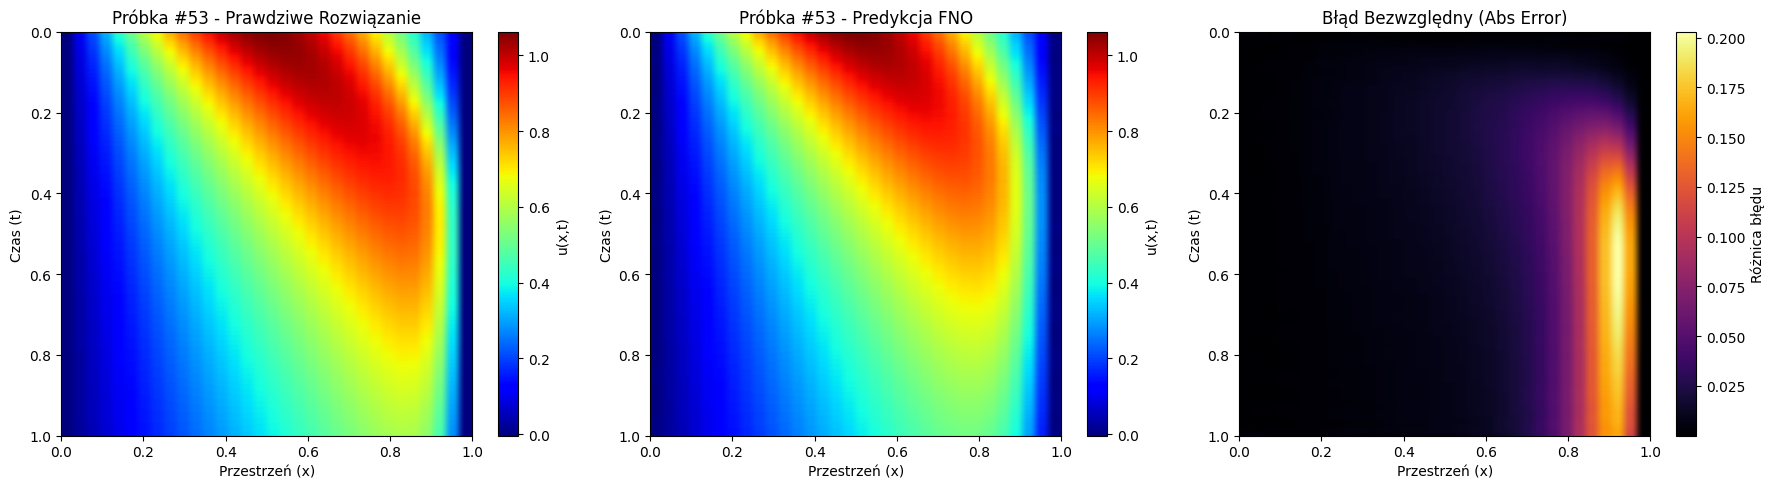

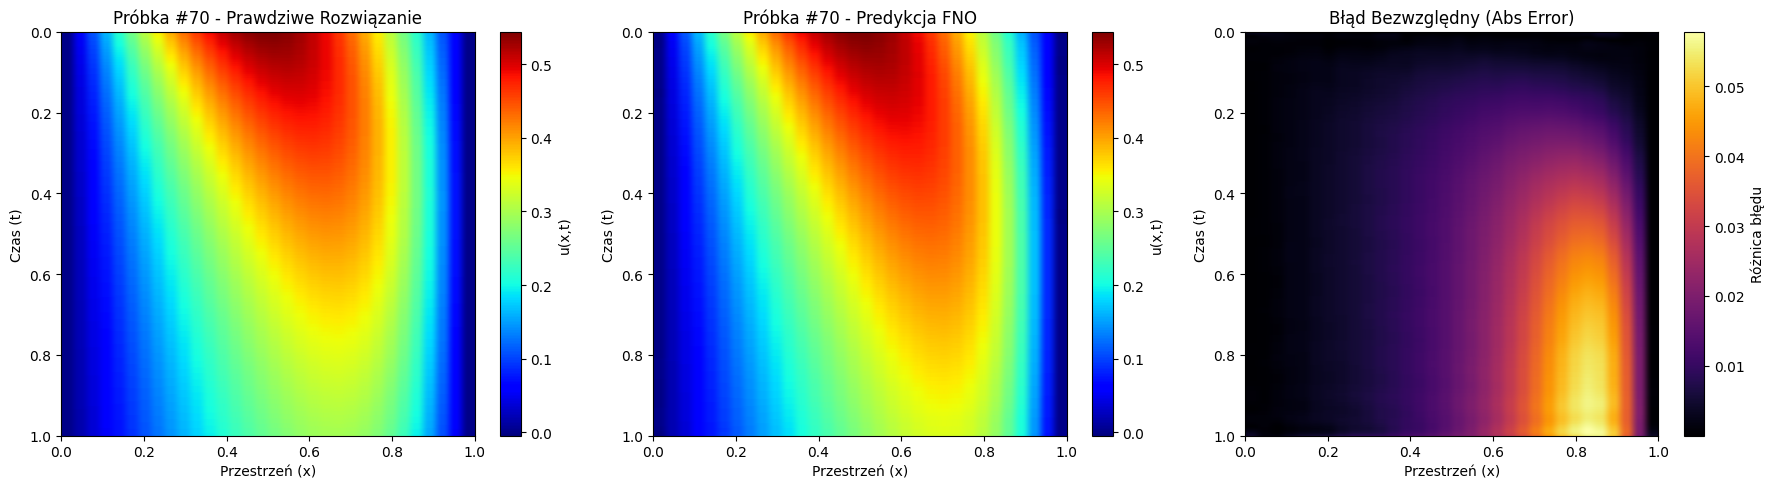

In [16]:
np.random.seed(42)
random_indices = np.random.choice(len(all_preds), size=3, replace=False)

for sample_idx in random_indices:
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # Calculate global limits across this specific sample to synchronize color scales
    vmin = min(all_targets[sample_idx].min(), all_preds[sample_idx].min())
    vmax = max(all_targets[sample_idx].max(), all_preds[sample_idx].max())

    # 1. Ground Truth Heatmap
    im0 = axes[0].imshow(
        all_targets[sample_idx],
        extent=[x_axis[0], x_axis[-1], time_axis[-1], time_axis[0]],
        aspect="auto",
        cmap="jet",
        vmin=vmin,
        vmax=vmax,
    )
    axes[0].set_title(f"Próbka #{sample_idx} - Prawdziwe Rozwiązanie")
    axes[0].set_ylabel("Czas (t)")
    axes[0].set_xlabel("Przestrzeń (x)")
    fig.colorbar(im0, ax=axes[0], label="u(x,t)")

    # 2. FNO Prediction Heatmap
    im1 = axes[1].imshow(
        all_preds[sample_idx],
        extent=[x_axis[0], x_axis[-1], time_axis[-1], time_axis[0]],
        aspect="auto",
        cmap="jet",
        vmin=vmin,
        vmax=vmax,
    )
    axes[1].set_title(f"Próbka #{sample_idx} - Predykcja FNO")
    axes[1].set_ylabel("Czas (t)")
    axes[1].set_xlabel("Przestrzeń (x)")
    fig.colorbar(im1, ax=axes[1], label="u(x,t)")

    # 3. Absolute Error Contour Map
    im2 = axes[2].imshow(
        abs_error_map[sample_idx],
        extent=[x_axis[0], x_axis[-1], time_axis[-1], time_axis[0]],
        aspect="auto",
        cmap="inferno",
    )
    axes[2].set_title("Błąd Bezwzględny (Abs Error)")
    axes[2].set_ylabel("Czas (t)")
    axes[2].set_xlabel("Przestrzeń (x)")
    fig.colorbar(im2, ax=axes[2], label="Różnica błędu")

    plt.tight_layout()

    # Save out analysis sheets individually
    plot3_path = os.path.join(
        output_dir, f"3_sample_{sample_idx}_contour_analysis_burgers.png"
    )
    plt.savefig(plot3_path, dpi=300, bbox_inches="tight")
    plt.show()